# Principal Component Analysis

PCA is a dimensionality reduction technique; it lets you distill multi-dimensional data down to fewer dimensions, selecting new dimensions that preserve variance in the data as best it can. (Basicamente pegar uma imagem com várias dimensões e reduzir para 2D, a fim de analisar os dados de uma forma viável)

We're not talking about Star Trek stuff here; let's make it real - a black & white image for example, contains three dimensions of data: X position, Y position, and brightness at each point. Distilling that down to two dimensions can be useful for things like image compression and facial recognition, because it distills out the information that contributes most to the variance in the data set.

Let's do this with a simpler example: the Iris data set that comes with scikit-learn. It's just a small collection of data that has four dimensions of data for three different kinds of Iris flowers: The length and width of both the petals and sepals of many individual flowers from each species. Let's load it up and have a look:

In [15]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import pylab as pl
from itertools import cycle

iris = load_iris() #aqui carregamos a parte interessante da flor
#abaixo extrai os dados das dimensões - 4D
numSamples, numFeatures = iris.data.shape
print(numSamples) #amostra
print(numFeatures)#dimenssões
print(list(iris.target_names)) #nomes

150
4
[np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [16]:
X = iris.data
pca = PCA(n_components=2, whiten=True).fit(X)
X_pca = pca.transform(X)

In [17]:
print(pca.components_) #aqui é para ver que algo está acontecendo

[[ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
 [ 0.65658877  0.73016143 -0.17337266 -0.07548102]]


In [18]:
print(pca.explained_variance_ratio_) #raio da variancia na flor
print(sum(pca.explained_variance_ratio_))

[0.92461872 0.05306648]
0.9776852063187963


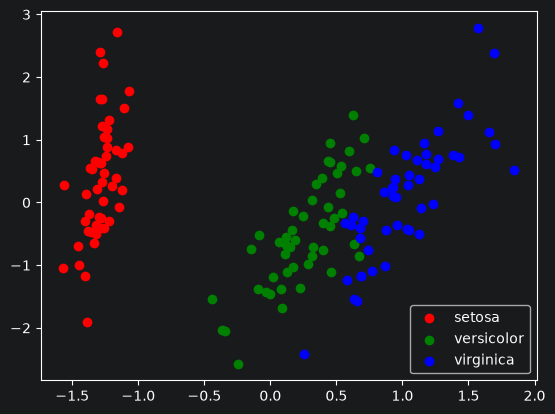

In [19]:
colors = cycle('rgb')
target_ids = range(len(iris.target_names))

pl.figure()
for i, c, label in zip(target_ids, colors, iris.target_names):
    pl.scatter(X_pca[iris.target == i, 0], X_pca[iris.target == i, 1],
               c=c, label=label)

pl.legend()
pl.show() #aqui colocamos em uma forma visual para enfim separar por grupo